# Data Mining project: cleaning of the `health` data

* Group: Group 10

This notebook cleans the 7 files of the `data/health/` folder and writes clean versions to `data/health_clean/`. The analysis is done in a second notebook, starting from these files.

Cleaning always involves making choices, and every choice can bias the analysis. We therefore set ourselves three rules:
* we only delete a row when we are sure it is an error (an exact duplicate, for example);
* we do not fill in a missing value when its absence is meaningful;
* we do not delete extreme values, we flag them. The goal of the project is to find a hidden story, and it is likely to lie precisely in these values.

Each correction is recorded in a log (`cleaning_log.csv`) with the number of modified cells.

*Use of generative AI: this work was done with the help of Claude (Anthropic). The assistant wrote most of the code and texts, and proposed methods and interpretation leads. On our side, we chose the steps, discussed and validated every cleaning and analysis decision, reviewed the results, and asked for corrections when a figure or an interpretation did not hold.*

## 1. Loading and first overview

We load everything as text, without letting pandas interpret the values: otherwise it would silently turn `"NA"` or `"null"` into missing values, and we could no longer measure these problems.

The files form a small relational database: a patient has encounters, and each encounter can have measurements, procedures, notes and cardiac recordings (themselves split into signal samples).

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

RAW, OUT = Path("../data/health"), Path("../data/health_clean")
OUT.mkdir(exist_ok=True)

TABLES = ["patient_administration", "clinical_encounters", "clinical_observations", "clinical_procedures",
          "cardiac_recordings", "cardiac_signal_samples", "clinical_notes"]
PK = {"patient_administration": ["patient_number"], "clinical_encounters": ["encounter_number"],
      "clinical_observations": ["observation_number"], "clinical_procedures": ["procedure_record_id"],
      "cardiac_recordings": ["recording_id"], "cardiac_signal_samples": ["recording_id", "time_ms"],
      "clinical_notes": ["document_id"]}
DATE_COLS = {"patient_administration": ["date_of_birth", "registration_date"],
             "clinical_encounters": ["encounter_start", "encounter_end", "follow_up_date"],
             "clinical_observations": ["observation_time"],
             "clinical_procedures": ["scheduled_time", "performed_time", "next_review_date"],
             "cardiac_recordings": ["recording_date"], "clinical_notes": ["document_date"]}
MISSING = {"", "null", "NA", "N/A"}
ISO = re.compile(r"^\d{4}-\d{2}-\d{2}(T\d{2}:\d{2}:\d{2})?$")

raw = {t: pd.read_csv(RAW / f"{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}
df = {t: d.copy() for t, d in raw.items()}

cleaning_entries = []
def log(table, action, n):
    if n:
        cleaning_entries.append({"table": table, "action": action, "n": int(n)})

def text_columns(d):
    return [c for c in d.columns if pd.api.types.is_object_dtype(d[c]) or pd.api.types.is_string_dtype(d[c])]

def extra_spaces(v):
    return isinstance(v, str) and v != " ".join(v.split())

def non_iso_date(v):
    return isinstance(v, str) and v not in MISSING and not ISO.match(v)

def data_audit(tables):
    rows = {}
    for t, d in tables.items():
        columns = text_columns(d)
        if t == "clinical_notes":
            columns.remove("text")   # the body of the notes is free text
        txt = d[columns]
        n_dates = 0
        for c in DATE_COLS.get(t, []):
            if c in d.columns:
                n_dates += d[c].map(non_iso_date).sum()
        rows[t] = {
            "rows": len(d),
            "duplicates": d.duplicated().sum(),
            "missing written as text": txt.isin(MISSING - {""}).sum().sum(),
            "extra spaces": txt.map(extra_spaces).sum().sum(),
            "dates not in standard format": n_dates,
        }
    return pd.DataFrame(rows).T

before = data_audit(raw)
before

,rows,duplicates,missing written as text,extra spaces,dates not in standard format
patient_administration,241,1,0,3,2
clinical_encounters,1069,2,3,3,10
clinical_observations,17736,2,55,50,0
clinical_procedures,311,1,1,1,3
cardiac_recordings,44,0,0,0,0
cardiac_signal_samples,96925,0,0,0,0
clinical_notes,30,0,0,0,0


There are few errors (a few dozen cells out of about 140,000 rows), but they are of very varied nature. The two cardiac files are clean. This table misses problems we found by looking at the columns one by one: inconsistent capitalisation and numbers written with a comma or followed by their unit.

## 2. Duplicates

We display the duplicate rows before deleting them, to check that they are identical on all columns.

In [2]:
for t in TABLES:
    d = df[t]
    if d.duplicated().any():
        display(d[d.duplicated(keep=False)].iloc[:, :6])
    log(t, "exact duplicate removed", d.duplicated().sum())
    df[t] = d.drop_duplicates().reset_index(drop=True)
    assert not df[t].duplicated(subset=PK[t]).any()   # every identifier is now unique

p = df["patient_administration"]
same_person = (p["family_name"].str.strip().str.lower() + p["given_name"].str.lower() + p["date_of_birth"]).duplicated().sum()
print("Patients with the same name, first name and date of birth under two numbers:", same_person)

,patient_number,family_name,given_name,date_of_birth,registered_sex,home_region
173,PAT-31045,Garen,Olia,2000-08-01,female,Nordhaven Union
240,PAT-31045,Garen,Olia,2000-08-01,female,Nordhaven Union


,encounter_number,patient_number,encounter_start,encounter_end,facility_license_number,encounter_type
732,ENC-000733,PAT-31066,2023-06-17T12:15:00,2023-06-17T13:59:00,FAC-VLN-101,general_examination
845,ENC-000846,PAT-31108,2022-05-04T12:15:00,2022-05-04T13:25:00,FAC-AVL-201,occupational_assessment
1067,ENC-000846,PAT-31108,2022-05-04T12:15:00,2022-05-04T13:25:00,FAC-AVL-201,occupational_assessment
1068,ENC-000733,PAT-31066,2023-06-17T12:15:00,2023-06-17T13:59:00,FAC-VLN-101,general_examination


,observation_number,encounter_number,patient_number,observation_time,observation_code,observation_name
3235,OBS-0003236,ENC-000245,PAT-31192,2021-09-01T11:32:00,MOBILITY,Mobility score
15194,OBS-0015195,ENC-000436,PAT-31157,2022-12-05T13:58:00,BINOCOORD,Binocular coordination
17734,OBS-0015195,ENC-000436,PAT-31157,2022-12-05T13:58:00,BINOCOORD,Binocular coordination
17735,OBS-0003236,ENC-000245,PAT-31192,2021-09-01T11:32:00,MOBILITY,Mobility score


,procedure_record_id,encounter_number,patient_number,procedure_code,procedure_description,scheduled_time
262,PRC-000263,ENC-000334,PAT-31107,CARD-IMG,Advanced cardiac imaging,2021-10-31T09:35:00
310,PRC-000263,ENC-000334,PAT-31107,CARD-IMG,Advanced cardiac imaging,2021-10-31T09:35:00


Patients with the same name, first name and date of birth under two numbers: 0


We remove 6 duplicate rows: 1 patient, 2 encounters, 2 measurements and 1 procedure. No person appears under two different numbers.

## 3. Text: spaces, capitalisation, labels

The same value is sometimes written in several ways: `"  Regional  executive "`, `ACTIVE` instead of `active`, `vALENNE rEPUBLIC` instead of `Valenne Republic`. We fix it in three steps:
* we remove extra spaces everywhere, except in the body of the notes, where we only standardise line breaks;
* we lowercase the code columns (`follow_up_planned`, `within_expected_range`…), since this is already how almost all rows are written;
* for labels in everyday language (region, measurement name, procedure name), we keep the most frequent spelling.

We do not touch identifiers, measurement codes (`RPULSE`) or units (`mmHg`).

In [3]:
CODES = {"patient_administration": ["registered_sex", "record_status"],
         "clinical_encounters": ["encounter_type", "referral_source", "service_unit", "disposition", "confidentiality_class"],
         "clinical_observations": ["text_value", "interpretation_code", "quality_code"],
         "clinical_procedures": ["authorization_class", "procedure_status", "outcome_code"],
         "cardiac_recordings": ["recording_context", "automated_interpretation", "recording_notes_code", "archive_status"],
         "clinical_notes": ["document_type", "confidentiality_class"]}
LABELS = {"patient_administration": ["home_region"], "clinical_observations": ["observation_name"],
          "clinical_procedures": ["procedure_description"]}

def majority_spelling(s):
    ref = s.groupby(s.str.lower()).agg(lambda x: x.value_counts().idxmax())
    return s.str.lower().map(ref)

for t, d in df.items():
    for c in text_columns(d):
        if t == "clinical_notes" and c == "text":
            d[c] = d[c].str.replace("\r\n", "\n").str.strip()
            continue
        clean = d[c].map(lambda v: " ".join(v.split()))
        log(t, f"extra spaces: {c}", (clean != d[c]).sum())
        d[c] = clean
    for c in CODES.get(t, []):
        clean = d[c].where(d[c].isin(MISSING), d[c].str.lower())   # NA/null are handled below
        log(t, f"capitalisation: {c}", (clean != d[c]).sum())
        d[c] = clean
    for c in LABELS.get(t, []):
        clean = majority_spelling(d[c])
        log(t, f"majority spelling: {c}", (clean != d[c]).sum())
        d[c] = clean

pd.DataFrame(cleaning_entries)

,table,action,n
0,patient_administration,exact duplicate removed,1
1,clinical_encounters,exact duplicate removed,2
2,clinical_observations,exact duplicate removed,2
3,clinical_procedures,exact duplicate removed,1
4,patient_administration,extra spaces: family_name,1
5,patient_administration,extra spaces: occupation_text,2
6,patient_administration,capitalisation: record_status,1
7,patient_administration,majority spelling: home_region,1
8,clinical_encounters,extra spaces: service_unit,3
9,clinical_encounters,capitalisation: encounter_type,5


The occupation (`occupation_text`) needs a special treatment. It is written in two styles: general categories in lowercase (`teacher`, `transport worker`…), and precise titles with a capital letter (`Head of government of Kintara Republic`, `Investigative reporter`…). This change of style could reveal a particular group of patients, so we do not erase it: we keep the original column and add a lowercase version, plus a "detailed title" indicator.

In [4]:
p = df["patient_administration"]
p["occupation_norm"] = p["occupation_text"].str.lower()
p["occupation_detailed"] = p["occupation_text"].str[0].str.isupper()
print("Patients with a detailed title:", p["occupation_detailed"].sum(), "out of", len(p))
p.loc[p["occupation_detailed"], "occupation_text"].value_counts().head(8)

Patients with a detailed title: 53 out of 240


occupation_text
Senior field analyst                3
Records researcher                  3
Grant officer                       3
Regional logistics manager          3
Senior executive-office official    3
Investigative reporter              2
Compliance counsel                  2
Regional executive                  2
Name: count, dtype: int64

53 patients have a detailed title: executives (head of government, ministers, CEOs) but also investigator profiles (journalist, analyst, archive researcher). This group will be compared with the others in the analysis.

## 4. Formats: missing values, dates and numbers

**Missing values.** An absent value is written in four ways: empty, `null`, `NA` or `N/A`. We replace them all with a real missing value. Note that the word `none` in `text_value` does not mean "missing": it means "no impairment" (the scale is `none / mild / moderate / severe`), so we keep it.

**Dates.** Besides the standard format `2019-04-17T10:15:00`, we find `2019/09/01`, `19-Nov-2020` and `01/09/2019`. The last one is ambiguous: should it be read day/month or month/day? The data settle it. Other dates in this format start with a number greater than 12 (`28/12/2021`), so with the day. And all registration dates fall on the 1st of the month, which gives 1 September.

In [5]:
for t, d in df.items():
    for c in text_columns(d):
        log(t, f"null/NA/N/A -> missing: {c}", d[c].isin(MISSING - {""}).sum())
        d[c] = d[c].mask(d[c].isin(MISSING))

DATE_FORMATS = ["%Y-%m-%dT%H:%M:%S", "%Y-%m-%d", "%Y/%m/%d %H:%M:%S", "%Y/%m/%d",
                "%d/%m/%Y %H:%M:%S", "%d/%m/%Y", "%d-%b-%Y %H:%M:%S", "%d-%b-%Y"]
def read_date(v):
    if not isinstance(v, str):
        return pd.NaT
    for f in DATE_FORMATS:
        try:
            return pd.to_datetime(v, format=f)
        except ValueError:
            pass
    raise ValueError(f"unrecognised date: {v}")   # we prefer an error to a lost date

corrected = []
for t, cols in DATE_COLS.items():
    for c in cols:
        raw_dates = df[t][c]
        to_fix = raw_dates.notna() & ~raw_dates.fillna("").str.match(ISO)
        df[t][c] = raw_dates.map(read_date)
        log(t, f"date put back in standard format: {c}", to_fix.sum())
        corrected += [(raw_dates[i], df[t].at[i, c]) for i in raw_dates[to_fix].index]
pd.DataFrame(corrected, columns=["before", "after"])

,before,after
0,01/09/2019,2019-09-01 00:00:00
1,2019/09/01,2019-09-01 00:00:00
2,19-Nov-2020 12:15:00,2020-11-19 12:15:00
3,19/12/2018 09:15:00,2018-12-19 09:15:00
4,15/02/2021 11:15:00,2021-02-15 11:15:00
5,2022/09/16 13:15:00,2022-09-16 13:15:00
6,28/12/2021 11:31:00,2021-12-28 11:31:00
7,06/08/2022 14:01:00,2022-08-06 14:01:00
8,2021/05/15 13:00:00,2021-05-15 13:00:00
9,19-May-2020 13:11:00,2020-05-19 13:11:00


**Numbers.** In the measurements (`numeric_value`), about 340 values cannot be read as numbers: either they have a comma (`84,9`), or the unit is attached after them (`77.4 bpm`). Before removing the unit, we check that it is identical to the one in the `unit` column. If it were not, we would have to convert the value instead of just deleting the text.

In [6]:
o = df["clinical_observations"]
parts = o["numeric_value"].str.extract(r"^(-?\d+(?:[.,]\d+)?)\s*(.*)$")
comma = parts[0].str.contains(",", na=False)
attached_unit = parts[1].fillna("") != ""
print("commas:", comma.sum(), "| attached units:", attached_unit.sum(),
      "| unit different from the 'unit' column:", (attached_unit & (parts[1] != o["unit"])).sum())

o["numeric_value"] = parts[0].str.replace(",", ".").astype(float)
log("clinical_observations", "comma replaced by a point: numeric_value", comma.sum())
log("clinical_observations", "attached unit removed: numeric_value", attached_unit.sum())

for c in ["sampling_rate_hz", "sampling_interval_ms", "channel_count", "sample_count"]:
    df["cardiac_recordings"][c] = df["cardiac_recordings"][c].astype(int)
for c in ["duration_seconds", "device_quality"]:
    df["cardiac_recordings"][c] = df["cardiac_recordings"][c].astype(float)
s = df["cardiac_signal_samples"]
s["time_ms"] = s["time_ms"].astype(int)
s[["channel_a_normalized", "channel_b_normalized"]] = s[["channel_a_normalized", "channel_b_normalized"]].astype(float)

commas: 180 | attached units: 160 | unit different from the 'unit' column: 0


All attached units match the `unit` column, and each type of measurement uses a single unit. So there is no conversion to do.

## 5. Useless or repeated columns

We remove three kinds of columns:
* those that have a single value, and therefore teach us nothing;
* those that can be recomputed from another one (the sampling interval is 1000 / frequency);
* those that repeat on every row although they only depend on a code: the name, unit and normal range of a measurement only depend on its code (`RPULSE`…). We put them in a small reference table, a "catalog", rather than copying them over 17,734 rows.

We check each relationship before deleting anything.

In [7]:
constants = [(t, c, d[c].iloc[0]) for t, d in df.items() for c in d.columns if d[c].nunique(dropna=False) <= 1]
display(pd.DataFrame(constants, columns=["table", "column", "single value"]))
for t, c, v in constants:
    df[t] = df[t].drop(columns=c)
    log(t, f"constant column removed: {c}", len(df[t]))

cr = df["cardiac_recordings"]
n_signal = df["cardiac_signal_samples"].groupby("recording_id").size()
assert (cr["sampling_interval_ms"] == 1000 / cr["sampling_rate_hz"]).all()
assert (cr["sample_count"] == cr["sampling_rate_hz"] * cr["duration_seconds"]).all()
assert (cr["sample_count"] == cr["recording_id"].map(n_signal)).all()   # the signal is complete
df["cardiac_recordings"] = cr.drop(columns="sampling_interval_ms")
log("cardiac_recordings", "recomputable column removed: sampling_interval_ms", len(cr))

,table,column,single value
0,clinical_observations,quality_code,acceptable
1,clinical_procedures,procedure_status,completed
2,cardiac_recordings,channel_count,2
3,cardiac_recordings,amplitude_unit,normalized_unit
4,cardiac_recordings,archive_status,finalized
5,clinical_notes,superseded_document_id,NaN


These constant columns still teach us something: all procedures are completed, all recordings are archived and **all measurements are of "acceptable" quality**. The strange values we will see later are therefore not explained by a failed measurement. We now build the two catalogs.

In [8]:
o = df["clinical_observations"]
assert (o.groupby("observation_code")[["observation_name", "unit", "reference_range_text"]].nunique(dropna=False) == 1).all().all()

catalog = (o.groupby("observation_code")
             .agg(name=("observation_name", "first"), unit=("unit", "first"), range=("reference_range_text", "first"),
                  n_measures=("observation_number", "size"), n_numbers=("numeric_value", "count"))
             .reset_index())
catalog["type"] = np.where(catalog["n_numbers"] > 0, "number", "text")
bounds = catalog["range"].where(catalog["type"] == "number").str.split("–", expand=True)
catalog["range_min"], catalog["range_max"] = bounds[0].astype(float), bounds[1].astype(float)
df["clinical_observations"] = o.drop(columns=["observation_name", "unit", "reference_range_text"])
log("clinical_observations", "name/unit/range moved to the catalog", len(o))

pr = df["clinical_procedures"]
assert (pr.groupby("procedure_code")["procedure_description"].nunique() == 1).all()
procedure_catalog = pr.groupby(["procedure_code", "procedure_description"]).size().rename("n_procedures").reset_index()
df["clinical_procedures"] = pr.drop(columns="procedure_description")
log("clinical_procedures", "description moved to the procedure catalog", len(pr))

catalog[["observation_code", "name", "unit", "range", "n_measures", "type"]]

,observation_code,name,unit,range,n_measures,type
0,AGECOND,Age-related condition count,count,0–10,240,number
1,APICAL,Apical cardiac rate,bpm,50–110,1017,number
2,BALANCE,Balance score,index,0–100,947,number
3,BINOCOORD,Binocular coordination,NaN,normal; reduced; atypical; not tested,240,text
4,BIOAGE,Estimated biological age,years,18–100,934,number
5,CAMMATCH,Camera match confidence,index,0–100,240,number
6,CARDOUT,Estimated cardiac output,L/min,3.5–8.0,941,number
7,COGNITIVE,Cognitive score,index,0–100,948,number
8,CVRISK,Cardiovascular risk score,index,0–100,240,number
9,DIABP,Diastolic blood pressure,mmHg,50–110,240,number


The catalog shows that 14 measurements are taken at almost every encounter (pulse, saturation, biological age, scores…) and only 18 once per patient (blood pressure, vision, camera recognition, "identity consistency"…).

## 6. Missing values

Before deciding what to do with a missing value, we need to understand why it is missing. We look at each column concerned by crossing it with another column that could explain it.

In [9]:
missing_summary = pd.DataFrame([(t, c, d[c].isna().sum(), round(100 * d[c].isna().mean(), 1))
                                for t, d in df.items() for c in d.columns if d[c].isna().any()],
                               columns=["table", "column", "missing", "%"])
display(missing_summary)

o = df["clinical_observations"].merge(catalog[["observation_code", "type"]], on="observation_code")
e, pr = df["clinical_encounters"], df["clinical_procedures"]
display(pd.crosstab(o["type"], o["numeric_value"].notna(), colnames=["number filled in"]))
display(pd.crosstab(e["disposition"], e["follow_up_date"].notna(), colnames=["follow-up date filled in"]))
display(pd.crosstab(pr["procedure_code"], [pr["material_reference"].notna(), pr["next_review_date"].notna()],
                    colnames=["material filled in", "review planned"]))

,table,column,missing,%
0,clinical_encounters,referral_source,3,0.3
1,clinical_encounters,follow_up_date,240,22.5
2,clinical_observations,numeric_value,1870,10.5
3,clinical_observations,text_value,15864,89.5
4,clinical_observations,device_reference,4325,24.4
5,clinical_procedures,material_reference,260,83.9
6,clinical_procedures,next_review_date,56,18.1


number filled in,False,True
type,,
number,0,15864
text,1870,0


follow-up date filled in,False,True
disposition,,
annual_review,89,20
discharged,80,0
follow_up_as_needed,71,0
follow_up_planned,0,807


material filled in False       True 
review planned     False True  True 
procedure_code                      
AGE-PNL               11    28     0
AUT-REV                8    35     0
CARD-IMG               6    35     0
MOB-PNL                7    30     0
MRP-42                 0     0    50
OCC-PNL               10    39     0
OCT-TRK               14    37     0

Almost all gaps have a logical explanation:

| Column | Why it is empty | What we do |
|---|---|---|
| `numeric_value` / `text_value` | a measurement is either a number or a text, never both | nothing |
| `device_reference` | measurements taken once never go through a device; only 5 other values are missing | we leave it empty |
| `follow_up_date` | no date when the patient is discharged or seen again "as needed" | nothing, the absence is information |
| `material_reference` | only the `MRP-42` procedure administers a product | nothing |
| `next_review_date` | missing for 18% of the procedures, but never for `MRP-42` | we leave it empty |
| `referral_source` | 3 encounters, impossible to guess | we leave it empty |

We therefore delete no row and invent no value. In passing, the `MRP-42` procedure (*"Targeted metabolic resilience administration"*) draws attention: it is the only one where something is administered, it always has a planned follow-up, and some of these procedures are classified as "restricted-access research".

## 7. Extreme values

We distinguish two things:
* an **impossible** value (an encounter that ends before it starts, a patient born after their visit…) is an error to correct;
* an **unusual but possible** value may be exactly what we are looking for. We keep it, and we flag it.

In [10]:
p = df["patient_administration"]
e = df["clinical_encounters"].merge(p[["patient_number", "date_of_birth", "registration_date", "occupation_text"]], on="patient_number")
pr = df["clinical_procedures"]
age = (e["encounter_start"] - e["date_of_birth"]).dt.days / 365.25
duration = (e["encounter_end"] - e["encounter_start"]).dt.total_seconds() / 60

pd.Series({
    "registration before birth": (p["registration_date"] < p["date_of_birth"]).sum(),
    "age at encounter < 0 or > 110 years": ((age < 0) | (age > 110)).sum(),
    "encounter that ends before it starts": (duration <= 0).sum(),
    "encounter before registration": (e["encounter_start"] < e["registration_date"]).sum(),
    "follow-up date before the encounter": (e["follow_up_date"] < e["encounter_start"].dt.normalize()).sum(),
    "procedure performed before being scheduled": (pr["performed_time"] < pr["scheduled_time"]).sum(),
    "encounters of minors (possible, to check)": (age < 18).sum(),
}, name="count").to_frame()

,count
registration before birth,0
age at encounter < 0 or > 110 years,0
encounter that ends before it starts,0
encounter before registration,0
follow-up date before the encounter,0
procedure performed before being scheduled,0
"encounters of minors (possible, to check)",8


There is no impossible value. Before the cleaning, two cases seemed inconsistent (an encounter before registration, a procedure performed before its scheduling), but they only came from badly written dates.

On the other hand, we find 8 encounters of patients aged 15 to 17, and some of these patients are "retired" or "teachers". This is probably a data generation flaw. We do not know which of the two pieces of information is wrong, so we correct nothing and flag it. We also note an isolated encounter in January 2026 (`ENC-000039`), several months after all the others.

For the numeric measurements, we add two columns without touching the values:
* `out_of_ref_range`: the value falls outside the normal range given by the hospital;
* `outlier_iqr`: the value is very far from the other measurements of the same type (the classic boxplot rule).

In [11]:
o = df["clinical_observations"].merge(catalog[["observation_code", "type", "range_min", "range_max"]], on="observation_code")
o["out_of_ref_range"] = (o["numeric_value"] < o["range_min"]) | (o["numeric_value"] > o["range_max"])
q1 = o.groupby("observation_code")["numeric_value"].transform(lambda x: x.quantile(.25))
q3 = o.groupby("observation_code")["numeric_value"].transform(lambda x: x.quantile(.75))
o["outlier_iqr"] = (o["numeric_value"] < q1 - 1.5 * (q3 - q1)) | (o["numeric_value"] > q3 + 1.5 * (q3 - q1))

summary = (o[o["type"] == "number"].groupby("observation_code")
            .agg(min=("numeric_value", "min"), max=("numeric_value", "max"), range_min=("range_min", "first"),
                 range_max=("range_max", "first"), out_of_range=("out_of_ref_range", "sum"), extremes=("outlier_iqr", "sum")))
df["clinical_observations"] = o.drop(columns=["type", "range_min", "range_max"])
log("clinical_observations", "flagged as outside the normal range (kept)", o["out_of_ref_range"].sum())
log("clinical_observations", "flagged as extreme (kept)", o["outlier_iqr"].sum())
summary[(summary["out_of_range"] > 0) | (summary["extremes"] > 10)].sort_values("out_of_range", ascending=False)

,min,max,range_min,range_max,out_of_range,extremes
observation_code,,,,,,
CARDOUT,3.0,9.6,3.5,8.0,38,20
BIOAGE,11.5,88.3,18.0,100.0,26,0
RPULSE,42.0,102.2,50.0,100.0,23,12
PPULSE,43.3,99.7,50.0,100.0,15,9
APICAL,42.0,106.7,50.0,110.0,10,3
O2SAT,92.5,100.0,94.0,100.0,10,2
SYSBP,88.0,155.3,90.0,180.0,2,4
STROKEVOL,35.8,104.1,45.0,120.0,2,1
COGNITIVE,57.2,100.0,0.0,100.0,0,14


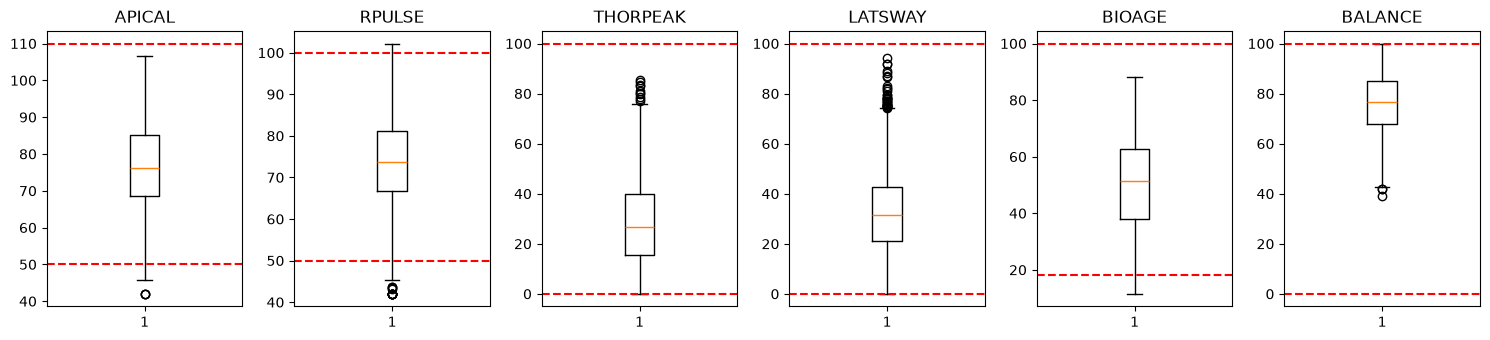

In [12]:
codes = catalog.loc[catalog["type"] == "number", "observation_code"].tolist()   # used at export

# a few interesting measurements; the red lines are the bounds of the normal range
to_show = ["APICAL", "RPULSE", "THORPEAK", "LATSWAY", "BIOAGE", "BALANCE"]
fig, axes = plt.subplots(1, 6, figsize=(15, 3.5))
for ax, c in zip(axes, to_show):
    ax.boxplot(o.loc[o["observation_code"] == c, "numeric_value"].dropna())
    ref = catalog.set_index("observation_code").loc[c]
    ax.axhline(ref["range_min"], color="red", linestyle="--")
    ax.axhline(ref["range_max"], color="red", linestyle="--")
    ax.set_title(c)
plt.tight_layout()
plt.show()

We keep all these values, for three reasons. None is impossible. All measurements are of "acceptable" quality. And the measurements that most often fall outside the norm are precisely those that the doctors' notes describe as odd: a pulse that differs depending on where it is taken (`APICAL` / `PPULSE`), a second beat in the chest (`THORPEAK`, `THORVIB`), a swaying gait (`LATSWAY`), a biological age under 18 in adults (`BIOAGE`). We therefore do not want to delete them.

The table and the chart also show that many scores are stuck at 100 (like `BALANCE`), and some pulses stuck at 42 (like `RPULSE`). These capped values slightly distort the means and the linear correlations, which we will have to keep in mind in the analysis.

## 8. Final check of the consistency between files

We check that every identifier cited in a file exists in the reference file, that a measurement, a procedure or a note concerns the same patient as its encounter, and that the dates follow each other in the right order.

In [13]:
P, E = df["patient_administration"], df["clinical_encounters"].set_index("encounter_number")
O, CR, N = df["clinical_observations"], df["cardiac_recordings"], df["clinical_notes"]
checks = {}
for t in ["clinical_observations", "clinical_procedures", "cardiac_recordings", "clinical_notes"]:
    d = df[t]
    checks[f"{t}: unknown encounter"] = (~d["encounter_number"].isin(E.index)).sum()
    checks[f"{t}: patient different from the encounter's"] = (d["patient_number"] != d["encounter_number"].map(E["patient_number"])).sum()
checks["encounter: unknown patient"] = (~E["patient_number"].isin(P["patient_number"])).sum()
checks["signal: unknown recording"] = (~df["cardiac_signal_samples"]["recording_id"].isin(CR["recording_id"])).sum()
checks["measurement taken outside the encounter's time slot"] = ((O["observation_time"] < O["encounter_number"].map(E["encounter_start"])) |
                                                                  (O["observation_time"] > O["encounter_number"].map(E["encounter_end"]))).sum()
checks["cardiac recording not on the day of the encounter"] = (CR["recording_date"] != CR["encounter_number"].map(E["encounter_start"]).dt.normalize()).sum()
display(pd.Series(checks, name="problems").to_frame())

gap = (N["document_date"] - N["encounter_number"].map(E["encounter_start"]).dt.normalize()).dt.days
print(f"Gap between a note and its encounter: from {gap.min()} to {gap.max()} days; {(gap < 0).sum()} notes out of 30 dated BEFORE")

,problems
clinical_observations: unknown encounter,0
clinical_observations: patient different from the encounter's,0
clinical_procedures: unknown encounter,0
clinical_procedures: patient different from the encounter's,0
cardiac_recordings: unknown encounter,0
cardiac_recordings: patient different from the encounter's,0
clinical_notes: unknown encounter,0
clinical_notes: patient different from the encounter's,0
encounter: unknown patient,0
signal: unknown recording,0


Gap between a note and its encounter: from -1249 to 2670 days; 8 notes out of 30 dated BEFORE


All checks are fine, with one exception: **the dates of the notes do not match those of their encounter**. The gap ranges from 3 years before to 7 years after, and 8 notes are dated before the encounter they are attached to. We correct nothing, but in the analysis we must not assume that a note was written on the day of the encounter. One case stands out: the only deceased patient (`PAT-31099`), last seen in 2018, has an imaging report dated December 2023. This point will have to be compared with the other datasets when we pool our results.

## 9. Export and summary

For the analysis, we also prepare a table with one row per encounter and one column per type of measurement (`observations_wide`).

In [14]:
O = df["clinical_observations"]
assert not O.duplicated(subset=["encounter_number", "observation_code"]).any()
value = O["numeric_value"].astype(object).where(O["numeric_value"].notna(), O["text_value"])
wide = O.assign(value=value).pivot(index="encounter_number", columns="observation_code", values="value")
wide[codes] = wide[codes].astype(float)
wide = df["clinical_encounters"][["encounter_number", "patient_number", "encounter_start", "encounter_type"]].merge(
    wide.reset_index(), on="encounter_number", how="left")

outputs = {**df, "observation_catalog": catalog, "procedure_catalog": procedure_catalog,
           "observations_wide": wide, "cleaning_log": pd.DataFrame(cleaning_entries)}
for name, d in outputs.items():
    d.to_csv(OUT / f"{name}.csv", index=False, date_format="%Y-%m-%dT%H:%M:%S")

after = data_audit(df)
pd.concat({"before": before, "after": after}, axis=1)

before                                                                               after                                                                             
                         rows duplicates missing written as text extra spaces dates not in standard format   rows duplicates missing written as text extra spaces dates not in standard format
patient_administration    241          1                       0            3                            2    240          0                       0            0                            0
clinical_encounters      1069          2                       3            3                           10   1067          0                       0            0                            0
clinical_observations   17736          2                      55           50                            0  17734          0                       0            0                            0
clinical_procedures       311          1                       1            1                            3    310          0                       0            0                            0
cardiac_recordings         44          0                       0            0                            0     44          0                       0            0                            0
cardiac_signal_samples  96925          0                       0            0                            0  96925          0                       0            0                            0
clinical_notes             30          0                       0            0                            0     30          0                       0            0                            0

**What was corrected:** 6 duplicates removed, spaces and capitalisation standardised, a single way of writing a missing value, dates all in the same format, about 340 numbers repaired, and useless columns removed or moved to catalogs. The details are in `cleaning_log.csv`.

**What was deliberately kept:** the missing values that have an explanation, all the extreme values (flagged by `out_of_ref_range` and `outlier_iqr`) and the writing style of occupations.

**Leads for the analysis:**
1. the `MRP-42` procedure and the administered material;
2. the group of 53 patients with a detailed title (executives and investigators);
3. the odd measurements (`APICAL`, `THORPEAK`, `LATSWAY`, `BIOAGE`, `IDCONS`): are they concentrated in certain patients?
4. 20 June 2025, when 22 encounters take place on the same day, 17 of them with measurements taken at exactly the same instants;
5. the isolated encounter of 2026 and the 2023 note about the deceased patient.